In [1]:
import os, shutil

dataset1 = "/kaggle/input/datasets/ngivitgccychui/rice-leaf-diseases-dataset-vbookshelf/Rice Leaf Diseases Dataset-vbookshelf"
dataset2 = "/kaggle/input/datasets/anshulm257/rice-disease-dataset/Rice_Leaf_AUG"

output_dir = "/kaggle/working/combined_dataset"

classes = [
    "Bacterial_leaf_blight",
    "Brown_spot",
    "Leaf_blast",
    "Sheath_blight",
    "Leaf_scald",
    "Healthy"
]

mapping = {
    "Bacterial leaf blight": "Bacterial_leaf_blight",
    "Brown spot": "Brown_spot",

    "Bacterial Leaf Blight": "Bacterial_leaf_blight",
    "Brown Spot": "Brown_spot",
    "Leaf Blast": "Leaf_blast",
    "Sheath Blight": "Sheath_blight",
    "Leaf scald": "Leaf_scald",
    "Healthy Rice Leaf": "Healthy"
}

shutil.rmtree(output_dir, ignore_errors=True)

for cls in classes:
    os.makedirs(os.path.join(output_dir, cls), exist_ok=True)

def copy_images(src):
    for class_name in os.listdir(src):
        path = os.path.join(src, class_name)
        if class_name not in mapping:
            continue
        
        target = os.path.join(output_dir, mapping[class_name])
        
        for file in os.listdir(path):
            shutil.copy(os.path.join(path, file), target)

copy_images(dataset1)
copy_images(dataset2)

print("✅ Dataset Ready")

✅ Dataset Ready


In [2]:
import tensorflow as tf

img_size = (300, 300)
batch_size = 32

train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    output_dir,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=img_size,
    batch_size=batch_size
)

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    output_dir,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=img_size,
    batch_size=batch_size
)

class_names = train_ds.class_names
print(class_names)

/usr/local/lib/python3.12/site-packages/jax/_src/cloud_tpu_init.py:93: UserWarning: Transparent hugepages are not enabled. TPU runtime startup and shutdown time should be significantly improved on TPU v5e and newer. If not already set, you may need to enable transparent hugepages in your VM image (sudo sh -c "echo always > /sys/kernel/mm/transparent_hugepage/enabled")
  warnings.warn(


Found 3909 files belonging to 6 classes.


Using 3128 files for training.


2026-03-27 15:34:18.954975: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Found 3909 files belonging to 6 classes.


Using 781 files for validation.


['Bacterial_leaf_blight', 'Brown_spot', 'Healthy', 'Leaf_blast', 'Leaf_scald', 'Sheath_blight']


In [3]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().shuffle(1000).prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)

In [4]:
from tensorflow.keras.applications.efficientnet import EfficientNetB0, preprocess_input

data_aug = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.3),
    tf.keras.layers.RandomZoom(0.3),
    tf.keras.layers.RandomContrast(0.3),
])

base_model = EfficientNetB0(
    input_shape=(300,300,3),
    include_top=False,
    weights='imagenet'
)

base_model.trainable = False

model = tf.keras.Sequential([
    data_aug,
    tf.keras.layers.Lambda(preprocess_input),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(6, activation='softmax')
])


       0/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step


 4202496/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [5]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [6]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(patience=2)
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10



 1/98 ━━━━━━━━━━━━━━━━━━━━ 13:43 8s/step - accuracy: 0.1562 - loss: 2.4983


 2/98 ━━━━━━━━━━━━━━━━━━━━ 57s 600ms/step - accuracy: 0.1641 - loss: 2.5714


 3/98 ━━━━━━━━━━━━━━━━━━━━ 56s 590ms/step - accuracy: 0.1858 - loss: 2.5362


 4/98 ━━━━━━━━━━━━━━━━━━━━ 55s 590ms/step - accuracy: 0.2057 - loss: 2.4738


 5/98 ━━━━━━━━━━━━━━━━━━━━ 53s 580ms/step - accuracy: 0.2221 - loss: 2.4126

... (990 outputs left out)


96/98 ━━━━━━━━━━━━━━━━━━━━ 1s 599ms/step - accuracy: 0.8336 - loss: 0.4554


97/98 ━━━━━━━━━━━━━━━━━━━━ 0s 599ms/step - accuracy: 0.8336 - loss: 0.4553


98/98 ━━━━━━━━━━━━━━━━━━━━ 0s 598ms/step - accuracy: 0.8336 - loss: 0.4553


98/98 ━━━━━━━━━━━━━━━━━━━━ 73s 745ms/step - accuracy: 0.8338 - loss: 0.4488 - val_accuracy: 0.8656 - val_loss: 0.3930 - learning_rate: 0.0010


In [7]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

In [8]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [9]:
model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10



 1/98 ━━━━━━━━━━━━━━━━━━━━ 16:50 10s/step - accuracy: 0.6562 - loss: 0.8948


 2/98 ━━━━━━━━━━━━━━━━━━━━ 1:10 733ms/step - accuracy: 0.6484 - loss: 0.9143


 3/98 ━━━━━━━━━━━━━━━━━━━━ 1:06 705ms/step - accuracy: 0.6649 - loss: 0.8856


 4/98 ━━━━━━━━━━━━━━━━━━━━ 1:08 725ms/step - accuracy: 0.6784 - loss: 0.8642


 5/98 ━━━━━━━━━━━━━━━━━━━━ 1:06 719ms/step - accuracy: 0.6890 - loss: 0.8500

... (990 outputs left out)


96/98 ━━━━━━━━━━━━━━━━━━━━ 1s 703ms/step - accuracy: 0.8105 - loss: 0.5057


97/98 ━━━━━━━━━━━━━━━━━━━━ 0s 704ms/step - accuracy: 0.8107 - loss: 0.5055


98/98 ━━━━━━━━━━━━━━━━━━━━ 0s 704ms/step - accuracy: 0.8108 - loss: 0.5053


98/98 ━━━━━━━━━━━━━━━━━━━━ 83s 851ms/step - accuracy: 0.8223 - loss: 0.4852 - val_accuracy: 0.8502 - val_loss: 0.4445


In [10]:
model.evaluate(val_ds)


 1/25 ━━━━━━━━━━━━━━━━━━━━ 14s 599ms/step - accuracy: 0.8438 - loss: 0.4175


 2/25 ━━━━━━━━━━━━━━━━━━━━ 13s 596ms/step - accuracy: 0.8438 - loss: 0.4238


 3/25 ━━━━━━━━━━━━━━━━━━━━ 12s 587ms/step - accuracy: 0.8472 - loss: 0.4047


 4/25 ━━━━━━━━━━━━━━━━━━━━ 12s 585ms/step - accuracy: 0.8503 - loss: 0.3958


 5/25 ━━━━━━━━━━━━━━━━━━━━ 11s 583ms/step - accuracy: 0.8515 - loss: 0.3937


 6/25 ━━━━━━━━━━━━━━━━━━━━ 11s 589ms/step - accuracy: 0.8519 - loss: 0.3937

... (17 outputs left out)


24/25 ━━━━━━━━━━━━━━━━━━━━ 0s 587ms/step - accuracy: 0.8542 - loss: 0.4192


25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 571ms/step - accuracy: 0.8541 - loss: 0.4203


25/25 ━━━━━━━━━━━━━━━━━━━━ 14s 571ms/step - accuracy: 0.8502 - loss: 0.4445


[0.44449904561042786, 0.8501920700073242]

In [11]:
import numpy as np

y_true = []
y_pred = []

for images, labels in val_ds:
    preds = model.predict(images)
    preds = np.argmax(preds, axis=1)
    
    y_true.extend(labels.numpy())
    y_pred.extend(preds)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 674ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 691ms/step



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 618ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 635ms/step


... (40 outputs left out)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 690ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 706ms/step



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


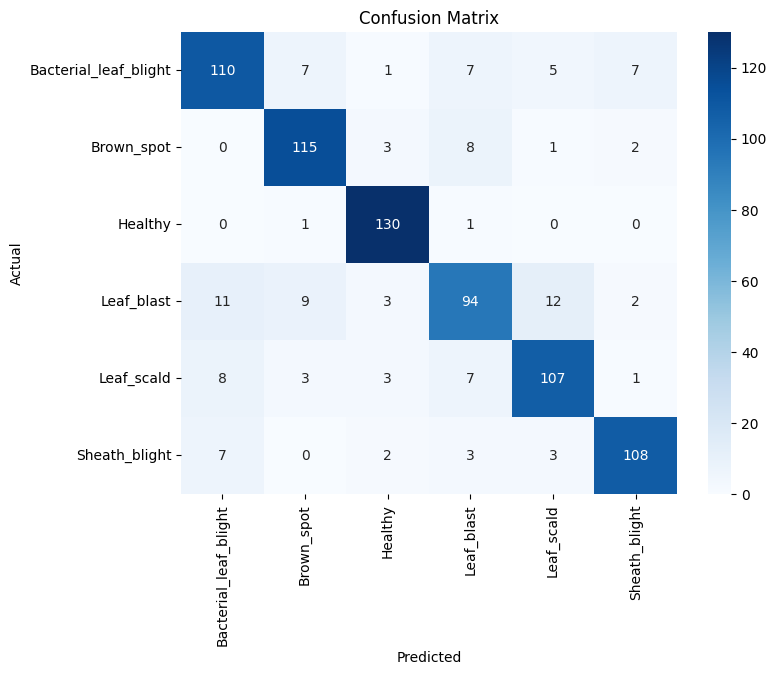

In [12]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [13]:
from sklearn.metrics import classification_report

report = classification_report(y_true, y_pred, target_names=class_names)
print(report)

                       precision    recall  f1-score   support

Bacterial_leaf_blight       0.81      0.80      0.81       137
           Brown_spot       0.85      0.89      0.87       129
              Healthy       0.92      0.98      0.95       132
           Leaf_blast       0.78      0.72      0.75       131
           Leaf_scald       0.84      0.83      0.83       129
        Sheath_blight       0.90      0.88      0.89       123

             accuracy                           0.85       781
            macro avg       0.85      0.85      0.85       781
         weighted avg       0.85      0.85      0.85       781



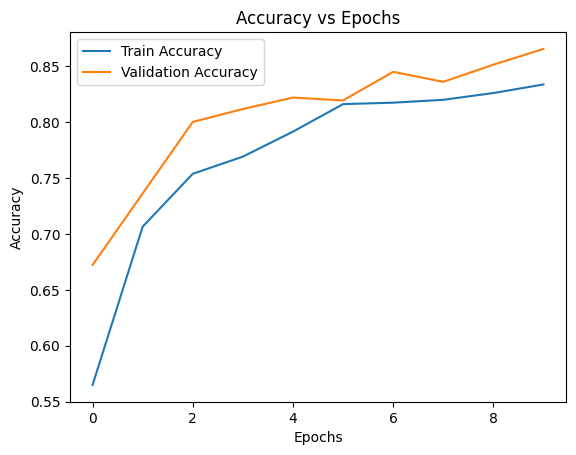

In [14]:
plt.figure()
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.title("Accuracy vs Epochs")
plt.show()

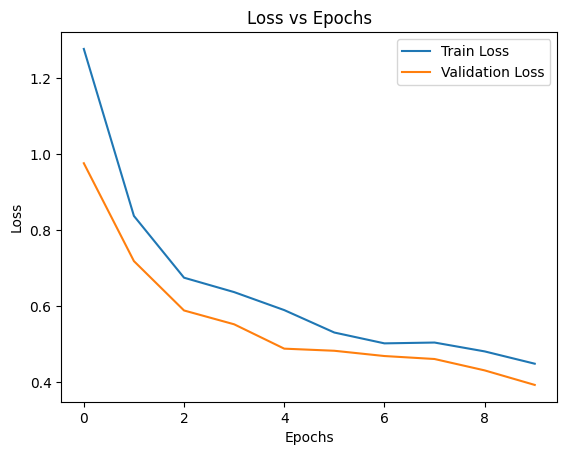

In [15]:
plt.figure()
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.title("Loss vs Epochs")
plt.show()

In [16]:
model.save("/kaggle/working/rice_model.keras")

In [17]:
import os

print(os.listdir("/kaggle/working"))

['__notebook__.ipynb', 'rice_model.keras', 'combined_dataset']


In [18]:
from tensorflow.keras.models import load_model
from tensorflow.keras.applications.efficientnet import preprocess_input

model = load_model(
    "rice_model.keras",
    custom_objects={"preprocess_input": preprocess_input},
    compile=False
)

In [19]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [20]:
from IPython.display import FileLink

FileLink('/kaggle/working/rice_model.keras')

/kaggle/working/rice_model.keras